## Milvus基本概念

Milvus是向量数据库，与MySQL这样的关系型数据库一样都是存储数据的，因此在概念上有很多相似之处。

### 1. Collection、Field、Entity

Milvus 中比较核心的概念有 3 个。它们与 MySQL 中的概念相似，但并不完全等价：

| Milvus | MySQL | 含义 |
| :--- | :--- | :--- |
| Collection | Table | 一组结构相同的数据集合 |
| Field | Column | 描述数据的某个属性，例如标题、文本、向量 |
| Entity | Row | Collection 中的一条完整数据 |




下图展示了一个包含 8 个 Field 和 6 个 Entity 的 Collection：

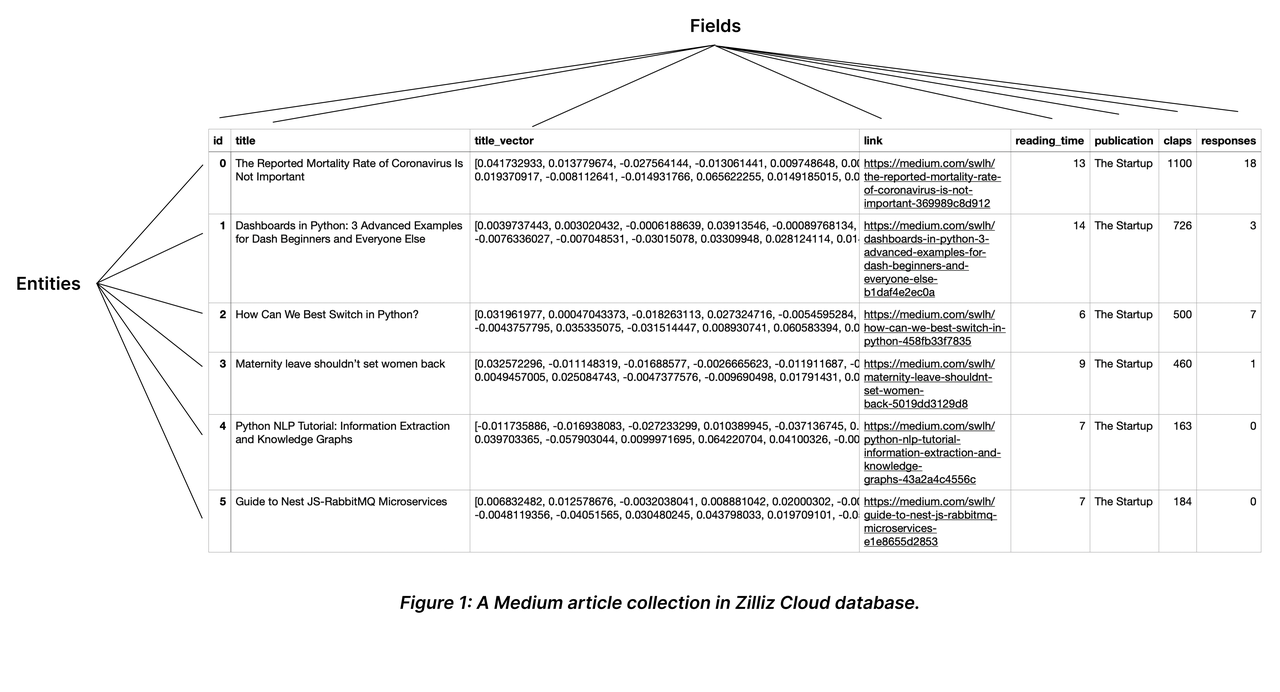

### 2. Schema
MySQL中需要定义表结构，Milvus中也需要定义Collection结构。在Milvus中Collection结构是由Schema来控制的。

`Schema` 用来定义 Collection 中包含哪些 Field，以及每个 Field 的名称、数据类型和相关属性。

常见的 Schema 属性可以按使用场景分为以下几类：

| 适用场景 | 属性 | 说明 |
| :--- | :--- | :--- |
| 通用 | `field_name` | 字段名称 |
| 通用 | `datatype` | 字段的数据类型 |
| 通用 | `description` | 字段说明 |
| 主键 | `is_primary` | 是否为主键 |
| 主键 | `auto_id` | 是否由 Milvus 自动生成主键 |
| 字符串 | `max_length` | 字符串字段的最大长度 |
| 向量 | `dim` | 向量的维度 |
| 数组 | `element_type` | 数组中元素的数据类型 |
| 数组 | `max_capacity` | 数组最多可以保存的元素数量 |



以上属性并不是每个字段都需要配置，而是根据具体的数据类型来选择，Milvus支持的数据类型有很多，常见的有：
- `VARCHAR`：也就是字符串，除了通用属性外，还需要设置max_length属性
- `INT32`、`INT64`：数字，通常设定通用属性即可
- `ARRAY`：数组，元素可以是其它类型，数组除了通用属性，还需要设定下列特有属性
  - element_type：数组中元素类型
  - max_capacity：数组元素数量
- 向量类型：下一节再细讲

在实际开发中，我们要根据文档的数据特点来选择合适的字段类型，例如官网给出的示例：

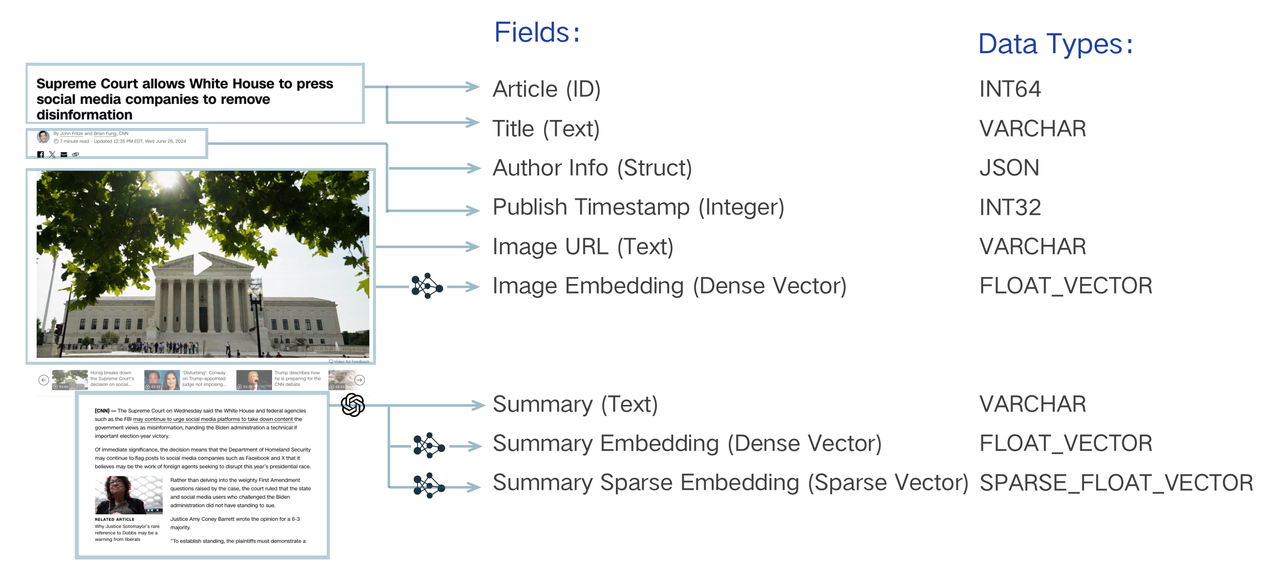

### 3. Index


`Index`，也就是索引，用来提高数据检索速度。根据字段的数据类型不同，Milvus 中常用的索引可以分为三类：

| 数据类型 | 保存的内容   | 常见索引 | 用途 |
| :---|:--------| :--- | :--- |
| 稠密向量 | 文本的语义特征 | `AUTOINDEX`、`HNSW`、`IVF_FLAT` | 加速向量相似度检索 |
| 稀疏向量 | 关键词及其权重 | `SPARSE_INVERTED_INDEX` | 加速稀疏向量检索 |
| 标量字段（普通字段）| 名称、分类、状态等业务数据        | `INVERTED`、`BITMAP` | 条件过滤，缩减向量检索范围 |

实际检索时，三类索引可以配合使用：
- 先用普通字段索引过滤数据，缩小数据检索范围，
- 再用稠密向量索引匹配语义，稀疏向量索引匹配关键词。

稠密向量和稀疏向量不是替代关系，而是互补关系，实际中经常会同时使用两种检索方式，也就是混合检索。

例如，一个保险产品文档切片：
```json
{
  "product_name": "达尔文12号重大疾病保险",
  "category": "重疾险",
  "content": "等待期后，被保人首次确诊合同约定的重大疾病，保险公司按照基本保险金额给付重大疾病保险金。"
}
```

保存到 Milvus 时，这条文档可以同时包含下面几类数据：

| Field | 示例数据 | 数据类型 | 作用 |
| :--- | :--- | :--- | :--- |
| `product_name` | 达尔文12号重大疾病保险 | 普通字段 | 条件过滤 |
| `category` | 重疾险 | 普通字段 | 条件过滤 |
| `content` | 等待期后，被保险人首次确诊...... | 普通字段 | 展示 |
| `dense_vector` | `[0.12, -0.35, 0.67, ...]` | 稠密向量 | 向量检索 |
| `sparse_vector` | `{1: 0.8, 3: 0.9, ...}` | 稀疏向量 | 向量检索 |

其中：
- `content`：也就是文档片段的原始内容，它的作用有两个，
  - 用来生成向量，
  - 作为查询结果返回，也就是RAG检索的文档原文
- `product_name`、`category` 是文档原本的字段，用于条件过滤。类似数据库的 `where key = value`
- `dense_vector`、`sparse_vector`属于是衍生字段，通常是根据 `content` 内容向量化得来。

标量字段，也就是普通字段是类似于where条件的过滤，比较简单。

但问题来了：
> 这里的稠密向量、稀疏向量是什么意思呢？

#### 3.1 稠密向量

学习RAG时，我们使用 Embedding 模型将文本转换成向量，再根据`向量相似度`检索`语义`相近的文档。这里生成的就是**稠密向量**。
```
[0.12, -0.35, 0.67, 0.28, ...]
```
稠密向量的维度是固定的，例如 `qwen3-embedding:0.6b` 生成的是 1024 维的向量。并且大部分位置都有数值，所以称为“稠密”。


稠密向量中的数值共同表示文本的语义，基于`稠密向量`的相似度检索就是基于`语义`的检索，即使用户使用了不同的表达方式，只要含义相近，哪怕是写错字也可能检索到相关内容。

例如：
- 原始文档：`2.1.免责声明：遇到以下情形之一，不予理赔...`
- 用户问题：`什么情况下保险不能赔？`

两句话用词不同，但语义接近，稠密向量检索通常能够找到对应文档。

#### 3.2 稀疏向量

如果说稠密向量是基于语义的检索，那`稀疏向量`则是基于`关键词`的检索。

稠密向量擅长理解语义，但在产品名称、疾病名称、条款编号等需要精确匹配的场景中不一定稳定。特别是一些专业词汇，一字之差意思就完全不同

例如，知识库中有两份保险条款：
- 文档 A：`本产品保障甲状腺乳头状癌。`
- 文档 B：`本产品保障甲状腺髓样癌。`

用户询问：“甲状腺髓样癌是否可以赔付？”

两份文档都包含“甲状腺”和“癌”，整体语义也非常接近。稠密向量检索可能认为它们都与问题高度相关，甚至把错误的文档 A 排在前面。

稀疏向量检索则会重点关注“髓样癌”这个关键词，使包含完全匹配词语的文档 B 获得更高分。

那么问题来了：
> 什么是稀疏向量呢？它如何实现关键词检索呢？

稀疏向量通常会有一份人类语言的**词表**。词表就是系统能够识别的所有词语集合，一个词表通常有几万到几十万词语，每个词语在向量中都有一个固定位置。例如下面这个简化的词表：

| 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | ... | 100000 |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| 医疗险 | 重疾险 | 意外险 | 被保人 | 等待期 | 保险金 | 投保年龄 | 保费 | 免责条款 | 续保 | ... | xxx |



文档转为稀疏向量，就是`把文档中出现的重要词语在词表对应位置上给权重值，其他位置则是 0`。示例文档含有：**被保人、等待期、保险金**，等词语，转换后的稀疏向量可以简化表示为：

```
[0, 0, 0, 0.9, 0.6, 0.7, 0, 0, 0, ......, 0]
```

实际系统中的词表可能包含几万甚至几十万词语，因此稀疏向量的维度通常很高。但是，一段文档只会涉及词表中的少量词语，所以绝大多数位置都是 `0`，这就是“**稀疏**”的含义。

为了节省存储空间，实际使用时不需要保存大量的 `0`，只需要记录非零位置和对应的权重：

```
{
    3: 0.9,
    4: 0.6,
    5: 0.7
}
```

比较稀疏向量相似度，就是看关键词的出现位置和权重等是否接近，所以**稀疏向量检索更擅长关键词的精确匹配检索**。例如：地名、人名、医疗词汇等专有名词或者编号。